In [1]:
import matplotlib.pyplot as plt
import plotly.express as px
import numpy as np
import seaborn as sns
# Machine Learning Libraries
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    RocCurveDisplay,
    PrecisionRecallDisplay
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier



from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [2]:
import requests
import pandas as pd
from pathlib import Path

api_url = "https://zenodo.org/api/records/11295916"

response = requests.get(api_url, timeout=60)
response.raise_for_status()

record = response.json()

csv_file = next(
    file for file in record["files"]
    if file["key"].endswith(".csv")
)

download_url = csv_file["links"]["self"]
file_path = Path("LC_loans_granting_model_dataset.csv")


if not file_path.exists():
    print("Downloading loan dataset...")

    with requests.get(
        download_url, stream=True, timeout=120
    ) as r:
        r.raise_for_status()

        with open(file_path, "wb") as f:
            for chunk in r.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk)

    print("Download complete!")

# Load the dataset
df = pd.read_csv(file_path, low_memory=False)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (1347681, 15)


,id,issue_d,revenue,dti_n,loan_amnt,fico_n,experience_c,emp_length,purpose,home_ownership_n,addr_state,zip_code,Default,title,desc
0,68407277,Dec-2015,55000.0,5.91,3600,677.0,1,10+ years,debt_consolidation,MORTGAGE,PA,190xx,0,Debt consolidation,NaN
1,68355089,Dec-2015,65000.0,16.06,24700,717.0,1,10+ years,small_business,MORTGAGE,SD,577xx,0,Business,NaN
2,68341763,Dec-2015,71000.0,13.85,20000,697.0,1,10+ years,home_improvement,MORTGAGE,IL,605xx,0,NaN,NaN
3,68476807,Dec-2015,104433.0,25.37,10400,697.0,1,3 years,major_purchase,MORTGAGE,PA,174xx,0,Major purchase,NaN
4,68426831,Dec-2015,34000.0,10.20,11950,692.0,1,4 years,debt_consolidation,RENT,GA,300xx,0,Debt consolidation,NaN


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1347681 entries, 0 to 1347680
Data columns (total 15 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   id                1347681 non-null  int64  
 1   issue_d           1347681 non-null  str    
 2   revenue           1347681 non-null  float64
 3   dti_n             1347681 non-null  float64
 4   loan_amnt         1347681 non-null  int64  
 5   fico_n            1347681 non-null  float64
 6   experience_c      1347681 non-null  int64  
 7   emp_length        1347681 non-null  str    
 8   purpose           1347681 non-null  str    
 9   home_ownership_n  1347681 non-null  str    
 10  addr_state        1347681 non-null  str    
 11  zip_code          1347680 non-null  str    
 12  Default           1347681 non-null  int64  
 13  title             1331024 non-null  str    
 14  desc              119099 non-null   str    
dtypes: float64(3), int64(4), str(8)
memory usage: 254.5 MB


In [4]:
missing = df.isnull().sum()
missing_percent = (missing / len(df) * 100)
missing_df = pd.DataFrame({'Missing Count': missing, 'Percentage': missing_percent})
print(missing_df[missing_df['Missing Count'] > 0].sort_values('Percentage', ascending=False))

          Missing Count  Percentage
desc            1228582   91.162671
title             16657    1.235975
zip_code              1    0.000074


In [5]:
# Drop columns that have more than 50% missing values
df= df.dropna(thresh=len(df) * 0.5, axis=1)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1347681 entries, 0 to 1347680
Data columns (total 14 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   id                1347681 non-null  int64  
 1   issue_d           1347681 non-null  str    
 2   revenue           1347681 non-null  float64
 3   dti_n             1347681 non-null  float64
 4   loan_amnt         1347681 non-null  int64  
 5   fico_n            1347681 non-null  float64
 6   experience_c      1347681 non-null  int64  
 7   emp_length        1347681 non-null  str    
 8   purpose           1347681 non-null  str    
 9   home_ownership_n  1347681 non-null  str    
 10  addr_state        1347681 non-null  str    
 11  zip_code          1347680 non-null  str    
 12  Default           1347681 non-null  int64  
 13  title             1331024 non-null  str    
dtypes: float64(3), int64(4), str(7)
memory usage: 222.1 MB


In [7]:
df.title.value_counts

<bound method IndexOpsMixin.value_counts of 0          Debt consolidation
1                    Business
2                         NaN
3              Major purchase
4          Debt consolidation
                  ...        
1347676      Home improvement
1347677    Debt consolidation
1347678      Home improvement
1347679      Medical expenses
1347680    Debt consolidation
Name: title, Length: 1347681, dtype: str>

In [8]:
# Replace null values in the 'purpose' column with "UNKNOWN"
df["title"] = df["title"].fillna("Unknown")

# Verify that there are no remaining nulls in the column
print("Null count in purpose:", df["title"].isnull().sum())

Null count in purpose: 0


In [9]:
missing = df.isnull().sum()
missing_percent = (missing / len(df) * 100)
missing_df = pd.DataFrame({'Missing Count': missing, 'Percentage': missing_percent})
print(missing_df[missing_df['Missing Count'] > 0].sort_values('Percentage', ascending=False))

          Missing Count  Percentage
zip_code              1    0.000074


In [10]:
# Convert the issue_d column to datetime
df["issue_d"] = pd.to_datetime(df["issue_d"], format="%b-%Y")

# Verify the new data type
print(df["issue_d"].dtype)

datetime64[us]


In [11]:
# Find the earliest and latest dates
min_date = df["issue_d"].min()
max_date = df["issue_d"].max()

print("Earliest date:", min_date)
print("Latest date:", max_date)

Earliest date: 2007-06-01 00:00:00
Latest date: 2018-12-01 00:00:00


In [12]:
df.issue_d

0         2015-12-01
1         2015-12-01
2         2015-12-01
3         2015-12-01
4         2015-12-01
             ...    
1347676   2016-10-01
1347677   2016-10-01
1347678   2016-10-01
1347679   2016-10-01
1347680   2016-10-01
Name: issue_d, Length: 1347681, dtype: datetime64[us]

In [13]:
# View all column names
print(df.columns.tolist())

['id', 'issue_d', 'revenue', 'dti_n', 'loan_amnt', 'fico_n', 'experience_c', 'emp_length', 'purpose', 'home_ownership_n', 'addr_state', 'zip_code', 'Default', 'title']


In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
# Count each loan outcome
loan_counts = df["Default"].value_counts().sort_index()

print(loan_counts)

Default
0    1078432
1     269249
Name: count, dtype: int64


In [16]:
# What percentage of loans ended in default?
label_map = {0: "Fully Paid", 1: "Defaulted"}
order = ["Fully Paid", "Defaulted"]

outcomes = df["Default"].map(label_map)

counts = outcomes.value_counts().reindex(order)
percentages = counts / counts.sum() * 100

summary = pd.DataFrame({
    "Loan Count": counts,
    "Percentage (%)": percentages
})
display(summary.round(2))

chart_df = counts.rename_axis("Loan Outcome").reset_index(name="Number of Loans")

fig = px.bar(
    chart_df,
    x="Loan Outcome",
    y="Number of Loans",
    text="Number of Loans",
    color="Loan Outcome",
    color_discrete_map={"Fully Paid": "#2E86AB", "Defaulted": "#E4572E"},
    title="Distribution of Loan Outcomes",
)

fig.update_traces(texttemplate="%{text:,.0f}", textposition="outside")
fig.update_layout(
    showlegend=False,
    width=800,
    height=500,
    yaxis_title="Number of Loans",
    xaxis_title="Loan Outcome",
    uniformtext_minsize=10,
)
fig.show()

print(f"Overall default rate: {df['Default'].mean() * 100:.2f}%")

,Loan Count,Percentage (%)
Default,,
Fully Paid,1078432,80.02
Defaulted,269249,19.98


Overall default rate: 19.98%


In [17]:
# Are larger loans associated with higher default rates?
bins = [0, 5000, 10000, 15000, 20000, 25000, 30000, np.inf]
labels = [
    "$0–5k", "$5k–10k", "$10k–15k",
    "$15k–20k", "$20k–25k", "$25k–30k", "$30k+"
]

loan_group = pd.cut(
    df["loan_amnt"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

loan_amount_results = df.groupby(
    loan_group, observed=False
).agg(
    total_loans=("Default", "size"),
    default_rate=("Default", "mean"),
    average_loan_amount=("loan_amnt", "mean")
)

loan_amount_results["default_rate"] *= 100

chart_df = loan_amount_results.reset_index().rename(
    columns={"loan_amnt": "Loan Amount Range"}
)
chart_df["Loan Amount Range"] = chart_df["Loan Amount Range"].astype(str)

fig = px.bar(
    chart_df,
    x="Loan Amount Range",
    y="default_rate",
    text="default_rate",
    hover_data={
        "total_loans": ":,",
        "average_loan_amount": ":$,.0f",
        "default_rate": ":.2f",
    },
    labels={
        "default_rate": "Default Rate (%)",
        "total_loans": "Total Loans",
        "average_loan_amount": "Avg Loan Amount",
    },
    title="Default Rate by Loan Amount",
)

fig.update_traces(
    texttemplate="%{text:.1f}%",
    textposition="outside",
    marker_color="#2E86AB",
)
fig.update_layout(
    width=900,
    height=500,
    xaxis_title="Loan Amount Range",
    yaxis_title="Default Rate (%)",
    xaxis_tickangle=-35,
    yaxis_range=[0, chart_df["default_rate"].max() * 1.15],
)
fig.show()

display(loan_amount_results.round(2))

,total_loans,default_rate,average_loan_amount
loan_amnt,,,
$0–5k,182926,15.81,3656.96
$5k–10k,374395,17.24,8104.58
$10k–15k,284123,20.78,13009.30
$15k–20k,214309,22.63,18142.30
$20k–25k,133199,22.81,23257.61
$25k–30k,77404,23.18,28469.82
$30k+,81325,24.48,34781.01


In [18]:
# How does credit score relate to default risk?
fico_bins = [0, 580, 620, 660, 700, 740, 850]
fico_labels = [
    "Below 580", "580–619", "620–659",
    "660–699", "700–739", "740+"
]

fico_group = pd.cut(
    df["fico_n"],
    bins=fico_bins,
    labels=fico_labels,
    include_lowest=True
)

fico_results = df.groupby(
    fico_group, observed=False
).agg(
    total_loans=("Default", "size"),
    default_rate=("Default", "mean"),
    average_fico=("fico_n", "mean")
)

fico_results["default_rate"] *= 100

# Chart
chart_df = fico_results.reset_index().rename(
    columns={"fico_n": "FICO Score Band"}
)
chart_df["FICO Score Band"] = chart_df["FICO Score Band"].astype(str)

fig = px.bar(
    chart_df,
    x="FICO Score Band",
    y="default_rate",
    text="default_rate",
    hover_data={
        "total_loans": ":,",
        "average_fico": ":.0f",
        "default_rate": ":.2f",
    },
    labels={
        "default_rate": "Default Rate (%)",
        "total_loans": "Total Loans",
        "average_fico": "Avg FICO",
    },
    title="Default Rate by FICO Score Band",
)

fig.update_traces(
    texttemplate="%{text:.1f}%",
    textposition="outside",
    marker_color="#2E86AB",
)
fig.update_layout(
    width=900,
    height=500,
    xaxis_title="FICO Score Band",
    yaxis_title="Default Rate (%)",
    xaxis_tickangle=-35,
    yaxis_range=[0, chart_df["default_rate"].max() * 1.15],
)
fig.show()

display(fico_results.round(2))

,total_loans,default_rate,average_fico
fico_n,,,
Below 580,0,NaN,NaN
580–619,3,33.33,613.67
620–659,486,30.86,649.49
660–699,822026,23.60,677.93
700–739,379874,16.08,715.61
740+,145292,9.65,767.15


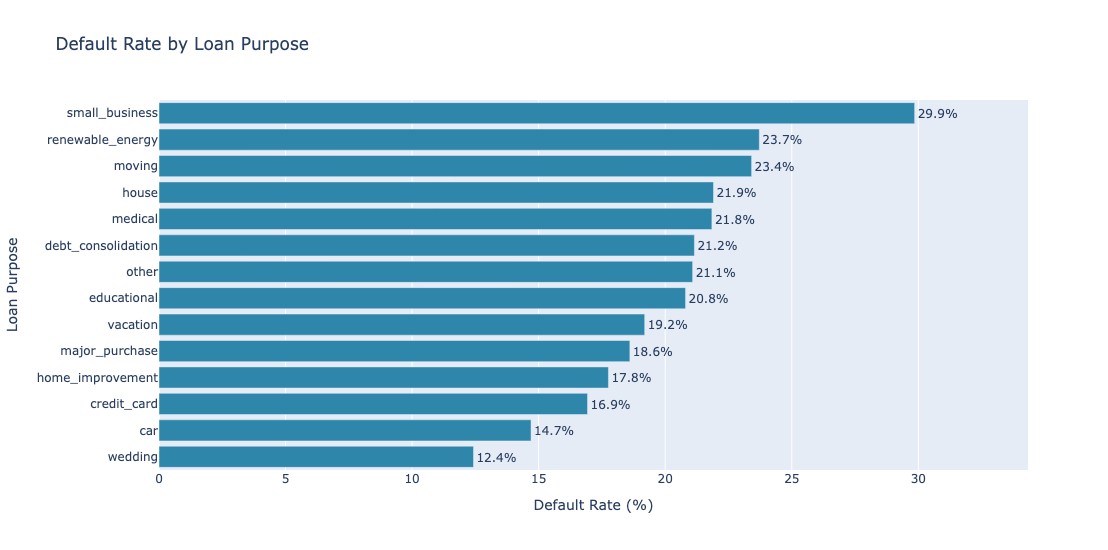

,total_loans,default_rate,average_loan_amount
purpose,,,
small_business,15575,29.86,15631.85
renewable_energy,936,23.72,10004.33
moving,9520,23.41,7852.97
house,7294,21.91,15354.47
medical,15606,21.84,8990.00
debt_consolidation,781206,21.15,15224.05
other,78263,21.08,9812.18
educational,423,20.80,6616.08
vacation,9083,19.19,6189.07


In [22]:
# Which loan purposes have the highest default rates?
purpose_results = df.groupby("purpose").agg(
    total_loans=("Default", "size"),
    default_rate=("Default", "mean"),
    average_loan_amount=("loan_amnt", "mean")
)

purpose_results["default_rate"] *= 100

purpose_ranked = purpose_results[
    purpose_results["total_loans"] >= 100
].sort_values("default_rate", ascending=False)

chart_df = purpose_ranked.reset_index().rename(
    columns={"purpose": "Loan Purpose"}
)

fig = px.bar(
    chart_df,
    x="default_rate",
    y="Loan Purpose",
    orientation="h",
    text="default_rate",
    hover_data={
        "total_loans": ":,",
        "average_loan_amount": ":$,.0f",
        "default_rate": ":.2f",
    },
    labels={
        "default_rate": "Default Rate (%)",
        "total_loans": "Total Loans",
        "average_loan_amount": "Avg Loan Amount",
    },
    title="Default Rate by Loan Purpose",
)

fig.update_traces(
    texttemplate="%{text:.1f}%",
    textposition="outside",
    marker_color="#2E86AB",
)
fig.update_layout(
    width=900,
    height=550,
    xaxis_title="Default Rate (%)",
    yaxis_title="Loan Purpose",
    yaxis_autorange="reversed",
    xaxis_range=[0, chart_df["default_rate"].max() * 1.15],
)
fig.show()

display(purpose_ranked.round(2))

In [23]:
# Does debt-to-income ratio relate to default risk?
dti_bins = [0, 10, 20, 30, 40, 50, np.inf]
dti_labels = [
    "0–10", "10–20", "20–30",
    "30–40", "40–50", "50+"
]

dti_group = pd.cut(
    df["dti_n"],
    bins=dti_bins,
    labels=dti_labels,
    include_lowest=True
)

dti_results = df.groupby(
    dti_group, observed=False
).agg(
    total_loans=("Default", "size"),
    default_rate=("Default", "mean"),
    average_dti=("dti_n", "mean")
)

dti_results["default_rate"] *= 100

# Chart
chart_df = dti_results.reset_index().rename(
    columns={"dti_n": "DTI Band"}
)
chart_df["DTI Band"] = chart_df["DTI Band"].astype(str)

fig = px.bar(
    chart_df,
    x="DTI Band",
    y="default_rate",
    text="default_rate",
    hover_data={
        "total_loans": ":,",
        "average_dti": ":.1f",
        "default_rate": ":.2f",
    },
    labels={
        "default_rate": "Default Rate (%)",
        "total_loans": "Total Loans",
        "average_dti": "Avg DTI",
    },
    title="Default Rate by Debt-to-Income Ratio",
)

fig.update_traces(
    texttemplate="%{text:.1f}%",
    textposition="outside",
    marker_color="#2E86AB",
)
fig.update_layout(
    width=800,
    height=500,
    xaxis_title="DTI Band",
    yaxis_title="Default Rate (%)",
    yaxis_range=[0, chart_df["default_rate"].max() * 1.15],
)
fig.show()

display(dti_results.round(2))

,total_loans,default_rate,average_dti
dti_n,,,
0–10,245652,14.84,6.48
10–20,563434,17.85,15.11
20–30,409868,23.08,24.42
30–40,121923,29.13,33.45
40–50,4024,32.01,44.28
50+,2780,28.74,103.20


In [24]:
# Which states have the highest loan default rates?
state_names = {
    "MS": "Mississippi", "NE": "Nebraska", "AR": "Arkansas",
    "AL": "Alabama", "OK": "Oklahoma", "LA": "Louisiana",
    "NY": "New York", "NV": "Nevada", "FL": "Florida", "IN": "Indiana",
}

state_results = df.groupby("addr_state").agg(
    total_loans=("Default", "size"),
    default_rate=("Default", "mean")
)

state_results["default_rate"] *= 100

state_ranked = (
    state_results[state_results["total_loans"] >= 100]
    .sort_values("default_rate", ascending=False)
    .head(10)
)

state_ranked.index = state_ranked.index.map(lambda s: state_names.get(s, s))
state_ranked.index.name = "State"

chart_df = state_ranked.reset_index()

fig = px.bar(
    chart_df,
    x="default_rate",
    y="State",
    orientation="h",
    text="default_rate",
    hover_data={
        "total_loans": ":,",
        "default_rate": ":.2f",
    },
    labels={
        "default_rate": "Default Rate (%)",
        "total_loans": "Total Loans",
    },
    title="10 States with the Highest Loan Default Rates",
)

fig.update_traces(
    texttemplate="%{text:.1f}%",
    textposition="outside",
    marker_color="#2E86AB",
)
fig.update_layout(
    width=900,
    height=550,
    xaxis_title="Default Rate (%)",
    yaxis_title="State",
    yaxis_autorange="reversed",
    xaxis_range=[0, chart_df["default_rate"].max() * 1.15],
)
fig.show()

display(state_ranked.round(2))

,total_loans,default_rate
State,,
Mississippi,6593,26.12
Nebraska,3591,25.20
Arkansas,10058,24.11
Alabama,16640,23.64
Oklahoma,12291,23.46
Louisiana,15520,23.17
New York,110075,22.05
Nevada,20282,21.98
Florida,95815,21.50


In [25]:
# How has default risk changed over time?
df["issue_d"] = pd.to_datetime(df["issue_d"], errors="coerce")
print(f"Unparseable dates dropped: {df['issue_d'].isna().sum():,}")

dated_loans = df.dropna(subset=["issue_d"]).copy()
dated_loans["issue_year"] = dated_loans["issue_d"].dt.year

yearly_results = dated_loans.groupby("issue_year").agg(
    total_loans=("Default", "size"),
    default_rate=("Default", "mean")
)

yearly_results["default_rate"] *= 100

chart_df = yearly_results.reset_index().rename(
    columns={"issue_year": "Issue Year"}
)

fig = px.line(
    chart_df,
    x="Issue Year",
    y="default_rate",
    markers=True,
    text="default_rate",
    hover_data={
        "total_loans": ":,",
        "default_rate": ":.2f",
    },
    labels={
        "default_rate": "Default Rate (%)",
        "total_loans": "Total Loans",
    },
    title="Loan Default Rate by Issue Year",
)

fig.update_traces(
    texttemplate="%{text:.1f}%",
    textposition="top center",
    line_color="#2E86AB",
)
fig.update_layout(
    width=900,
    height=500,
    xaxis_title="Loan Issue Year",
    yaxis_title="Default Rate (%)",
    xaxis=dict(dtick=1),
    yaxis_range=[0, chart_df["default_rate"].max() * 1.2],
)
fig.show()

display(yearly_results.round(2))

Unparseable dates dropped: 0


,total_loans,default_rate
issue_year,,
2007,599,26.38
2008,2393,20.73
2009,5281,13.69
2010,12537,14.01
2011,21721,15.18
2012,53367,16.20
2013,134804,15.60
2014,223102,18.45
2015,375543,20.18


In [27]:
employment_analysis = (
    df.groupby("emp_length", dropna=False)
    .agg(
        Total_Loans=("Default", "count"),
        Defaulted_Loans=("Default", "sum"),
        Average_Loan_Amount=("loan_amnt", "mean"),
    )
    .reset_index()
)

employment_analysis["Default_Rate"] = (
    employment_analysis["Defaulted_Loans"]
    / employment_analysis["Total_Loans"]
    * 100
).round(2)

employment_analysis = employment_analysis.sort_values(
    by="Default_Rate", ascending=False
)

chart_df = employment_analysis.copy()
chart_df["emp_length"] = chart_df["emp_length"].fillna("Missing").astype(str)

fig = px.bar(
    chart_df,
    x="emp_length",
    y="Default_Rate",
    text="Default_Rate",
    hover_data={
        "Total_Loans": ":,",
        "Defaulted_Loans": ":,",
        "Average_Loan_Amount": ":$,.0f",
        "Default_Rate": ":.2f",
    },
    labels={
        "emp_length": "Employment Length",
        "Default_Rate": "Default Rate (%)",
        "Total_Loans": "Total Loans",
        "Defaulted_Loans": "Defaulted Loans",
        "Average_Loan_Amount": "Avg Loan Amount",
    },
    title="Loan Default Rate by Employment Length",
)

fig.update_traces(
    texttemplate="%{text:.1f}%",
    textposition="outside",
    marker_color="#1f77b4",
)
fig.update_layout(
    width=900,
    height=550,
    xaxis_title="Employment Length",
    yaxis_title="Default Rate (%)",
    xaxis_tickangle=-45,
    yaxis_range=[0, chart_df["Default_Rate"].max() * 1.15],
)
fig.show()

# Display the summary table
display(employment_analysis.round(2))

,emp_length,Total_Loans,Defaulted_Loans,Average_Loan_Amount,Default_Rate
11,NI,78188,21077,11467.58,26.96
0,1 year,88841,18289,13451.58,20.59
10,< 1 year,108517,22289,13769.94,20.54
3,3 years,107862,21558,13861.99,19.99
8,8 years,60808,12132,14714.82,19.95
9,9 years,51019,10158,14826.13,19.91
2,2 years,122091,24197,13745.45,19.82
4,4 years,80761,15956,14003.75,19.76
5,5 years,84326,16545,14144.52,19.62
7,7 years,59724,11652,14539.71,19.51


In [28]:
df.emp_length.value_counts()

emp_length
10+ years    442667
2 years      122091
< 1 year     108517
3 years      107862
1 year        88841
5 years       84326
4 years       80761
NI            78188
6 years       62877
8 years       60808
7 years       59724
9 years       51019
Name: count, dtype: int64

In [29]:
df.dtypes

id                           int64
issue_d             datetime64[us]
revenue                    float64
dti_n                      float64
loan_amnt                    int64
fico_n                     float64
experience_c                 int64
emp_length                     str
purpose                        str
home_ownership_n               str
addr_state                     str
zip_code                       str
Default                      int64
title                          str
dtype: object

In [30]:
df.head()

,id,issue_d,revenue,dti_n,loan_amnt,fico_n,experience_c,emp_length,purpose,home_ownership_n,addr_state,zip_code,Default,title
0,68407277,2015-12-01,55000.0,5.91,3600,677.0,1,10+ years,debt_consolidation,MORTGAGE,PA,190xx,0,Debt consolidation
1,68355089,2015-12-01,65000.0,16.06,24700,717.0,1,10+ years,small_business,MORTGAGE,SD,577xx,0,Business
2,68341763,2015-12-01,71000.0,13.85,20000,697.0,1,10+ years,home_improvement,MORTGAGE,IL,605xx,0,Unknown
3,68476807,2015-12-01,104433.0,25.37,10400,697.0,1,3 years,major_purchase,MORTGAGE,PA,174xx,0,Major purchase
4,68426831,2015-12-01,34000.0,10.20,11950,692.0,1,4 years,debt_consolidation,RENT,GA,300xx,0,Debt consolidation


In [31]:
# Does credit score affect loan default rates?
bins = [600, 650, 700, 750, 800, 850]
labels = ["600–649", "650–699", "700–749", "750–799", "800–849"]

df["fico_group"] = pd.cut(
    df["fico_n"],
    bins=bins,
    labels=labels,
    right=False
)

fico_analysis = (
    df.groupby("fico_group", observed=False)
    .agg(
        Total_Loans=("Default", "count"),
        Defaulted_Loans=("Default", "sum"),
        Average_Loan_Amount=("loan_amnt", "mean")
    )
    .reset_index()
)

fico_analysis["Default_Rate"] = (
    fico_analysis["Defaulted_Loans"]
    / fico_analysis["Total_Loans"] * 100
).round(2)

# Chart
chart_df = fico_analysis.copy()
chart_df["fico_group"] = chart_df["fico_group"].astype(str)

fig = px.bar(
    chart_df,
    x="fico_group",
    y="Default_Rate",
    text="Default_Rate",
    hover_data={
        "Total_Loans": ":,",
        "Defaulted_Loans": ":,",
        "Average_Loan_Amount": ":$,.0f",
        "Default_Rate": ":.2f",
    },
    labels={
        "fico_group": "Credit Score Group",
        "Default_Rate": "Default Rate (%)",
        "Total_Loans": "Total Loans",
        "Defaulted_Loans": "Defaulted Loans",
        "Average_Loan_Amount": "Avg Loan Amount",
    },
    title="Loan Default Rate by Credit Score",
)

fig.update_traces(
    texttemplate="%{text:.1f}%",
    textposition="outside",
    marker_color="#2E86AB",
)
fig.update_layout(
    width=900,
    height=550,
    xaxis_title="Credit Score Group",
    yaxis_title="Default Rate (%)",
    yaxis_range=[0, chart_df["Default_Rate"].max() * 1.15],
)
fig.show()

display(fico_analysis)

,fico_group,Total_Loans,Defaulted_Loans,Average_Loan_Amount,Default_Rate
0,600–649,231,74,6454.220779,32.03
1,650–699,822284,194083,13676.970517,23.60
2,700–749,418569,65624,15653.013959,15.68
3,750–799,91152,8478,15140.309593,9.30
4,800–849,15445,990,15404.184202,6.41


In [32]:
y = df["Default"]

feature_columns = [
    "loan_amnt",
    "fico_n",
    "dti_n",
    "emp_length",
    "purpose",
    "home_ownership_n",
    "addr_state"
]

X = df[feature_columns].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeatures:")
print(X.head())

print("\nTarget:")
print(y.head())

X shape: (1347681, 7)
y shape: (1347681,)

Features:
   loan_amnt  fico_n  dti_n emp_length             purpose home_ownership_n  \
0       3600   677.0   5.91  10+ years  debt_consolidation         MORTGAGE   
1      24700   717.0  16.06  10+ years      small_business         MORTGAGE   
2      20000   697.0  13.85  10+ years    home_improvement         MORTGAGE   
3      10400   697.0  25.37    3 years      major_purchase         MORTGAGE   
4      11950   692.0  10.20    4 years  debt_consolidation             RENT   

  addr_state  
0         PA  
1         SD  
2         IL  
3         PA  
4         GA  

Target:
0    0
1    0
2    0
3    0
4    0
Name: Default, dtype: int64


In [33]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 1347681 entries, 0 to 1347680
Data columns (total 7 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   loan_amnt         1347681 non-null  int64  
 1   fico_n            1347681 non-null  float64
 2   dti_n             1347681 non-null  float64
 3   emp_length        1347681 non-null  str    
 4   purpose           1347681 non-null  str    
 5   home_ownership_n  1347681 non-null  str    
 6   addr_state        1347681 non-null  str    
dtypes: float64(2), int64(1), str(4)
memory usage: 110.7 MB


In [34]:
X.head()

,loan_amnt,fico_n,dti_n,emp_length,purpose,home_ownership_n,addr_state
0,3600,677.0,5.91,10+ years,debt_consolidation,MORTGAGE,PA
1,24700,717.0,16.06,10+ years,small_business,MORTGAGE,SD
2,20000,697.0,13.85,10+ years,home_improvement,MORTGAGE,IL
3,10400,697.0,25.37,3 years,major_purchase,MORTGAGE,PA
4,11950,692.0,10.20,4 years,debt_consolidation,RENT,GA


In [35]:
# Split
split_index = int(len(df) * 0.80)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

In [36]:
numeric_features = ["loan_amnt", "fico_n", "dti_n"]

categorical_features = [
    "emp_length",
    "purpose",
    "home_ownership_n",
    "addr_state"
]

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Preprocessing ready.")

Preprocessing ready.


In [37]:
decision_tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        max_depth=12,
        min_samples_leaf=100,
        class_weight="balanced",
        random_state=42
    ))
])

decision_tree_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['loan_amnt','fico_n','dti_n',...,'purpose','home_ownership_n', 'addr_state']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pass

In [38]:
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=16,
        min_samples_leaf=100,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    ))
])

random_forest_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['loan_amnt','fico_n','dti_n',...,'purpose','home_ownership_n', 'addr_state']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pass

In [39]:
models = {
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).set_index("Model")
results_df.round(4)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Decision Tree,0.6004,0.2804,0.6002,0.3822,0.6401
Random Forest,0.6092,0.2868,0.6036,0.3889,0.6505


In [40]:
from catboost import CatBoostClassifier

X_train_cb = X_train.copy()
X_test_cb = X_test.copy()

# Categories features
cat_features = [
    "emp_length",
    "purpose",
    "home_ownership_n",
    "addr_state"
]

for col in cat_features:
    X_train_cb[col] = X_train_cb[col].fillna("Unknown").astype(str)
    X_test_cb[col] = X_test_cb[col].fillna("Unknown").astype(str)

print("Training shape:", X_train_cb.shape)
print("Testing shape:", X_test_cb.shape)

Training shape: (1078144, 7)
Testing shape: (269537, 7)


In [41]:
catboost_model = CatBoostClassifier(
    iterations=800,
    depth=8,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=100,
    thread_count=-1,
    allow_writing_files=False
)

catboost_model.fit(
    X_train_cb,
    y_train,
    cat_features=cat_features,
    eval_set=(X_test_cb, y_test),
    early_stopping_rounds=100,
    verbose=100
)

0:	test: 0.6280066	best: 0.6280066 (0)	total: 830ms	remaining: 11m 3s
100:	test: 0.6558886	best: 0.6558886 (100)	total: 1m 12s	remaining: 8m 19s
200:	test: 0.6574899	best: 0.6574899 (200)	total: 2m 19s	remaining: 6m 56s
300:	test: 0.6579284	best: 0.6579284 (300)	total: 3m 25s	remaining: 5m 41s
400:	test: 0.6585428	best: 0.6585428 (400)	total: 4m 45s	remaining: 4m 44s
500:	test: 0.6588371	best: 0.6588379 (499)	total: 5m 58s	remaining: 3m 34s
600:	test: 0.6590690	best: 0.6590720 (588)	total: 7m 20s	remaining: 2m 25s
700:	test: 0.6591832	best: 0.6591832 (700)	total: 9m 3s	remaining: 1m 16s
799:	test: 0.6592671	best: 0.6592671 (799)	total: 10m 44s	remaining: 0us

bestTest = 0.6592671485
bestIteration = 799



CatBoostClassifier(allow_writing_files=False, depth=8, eval_metric='AUC', iterations=800, learning_rate=0.05, loss_function='Logloss', random_seed=42, verbose=100)

In [42]:
y_pred_cb = catboost_model.predict(X_test_cb).ravel()
y_prob_cb = catboost_model.predict_proba(X_test_cb)[:, 1]

catboost_results = pd.DataFrame([{
    "Model": "CatBoost",
    "Accuracy": accuracy_score(y_test, y_pred_cb),
    "Precision": precision_score(y_test, y_pred_cb, zero_division=0),
    "Recall": recall_score(y_test, y_pred_cb, zero_division=0),
    "F1-Score": f1_score(y_test, y_pred_cb, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob_cb)
}]).set_index("Model")

In [43]:
catboost_results.round(4)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
CatBoost,0.7941,0.5203,0.0065,0.0128,0.6593


In [44]:
print("Actual test target distribution:")
print(pd.Series(y_test).value_counts())

print("\nCatBoost prediction distribution:")
print(pd.Series(y_pred_cb).value_counts())

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred_cb))

print("\nClassification report:")
print(classification_report(y_test, y_pred_cb, zero_division=0))


Actual test target distribution:
Default
0    214021
1     55516
Name: count, dtype: int64

CatBoost prediction distribution:
0    268847
1       690
Name: count, dtype: int64

Confusion matrix:
[[213690    331]
 [ 55157    359]]

Classification report:
              precision    recall  f1-score   support

           0       0.79      1.00      0.89    214021
           1       0.52      0.01      0.01     55516

    accuracy                           0.79    269537
   macro avg       0.66      0.50      0.45    269537
weighted avg       0.74      0.79      0.71    269537



In [45]:
print("Predicted default probability summary:")
print(pd.Series(y_prob_cb).describe())

print("\nPercentage predicted as default at different thresholds:")

for threshold in [0.5, 0.4, 0.3, 0.2, 0.1]:
    predictions = (y_prob_cb >= threshold).astype(int)

    print(
        f"Threshold {threshold:.1f}: "
        f"{predictions.mean() * 100:.2f}% predicted defaults"
    )


Predicted default probability summary:
count    269537.000000
mean          0.191788
std           0.090581
min           0.006954
25%           0.125625
50%           0.179820
75%           0.245829
max           0.654356
dtype: float64

Percentage predicted as default at different thresholds:
Threshold 0.5: 0.26% predicted defaults
Threshold 0.4: 2.49% predicted defaults
Threshold 0.3: 12.57% predicted defaults
Threshold 0.2: 41.30% predicted defaults
Threshold 0.1: 85.08% predicted defaults


In [46]:
threshold_results = []

for threshold in [0.50, 0.40, 0.30, 0.25, 0.20, 0.15, 0.10]:
    predictions = (y_prob_cb >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1_Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)
threshold_df.round(4)


,Threshold,Accuracy,Precision,Recall,F1_Score
0,0.50,0.7941,0.5203,0.0065,0.0128
1,0.40,0.7921,0.4613,0.0559,0.0996
2,0.30,0.7637,0.3794,0.2316,0.2876
3,0.25,0.7166,0.3374,0.3899,0.3618
4,0.20,0.6248,0.2951,0.5917,0.3938
5,0.15,0.4843,0.2578,0.8002,0.3899
6,0.10,0.3317,0.2283,0.9430,0.3676


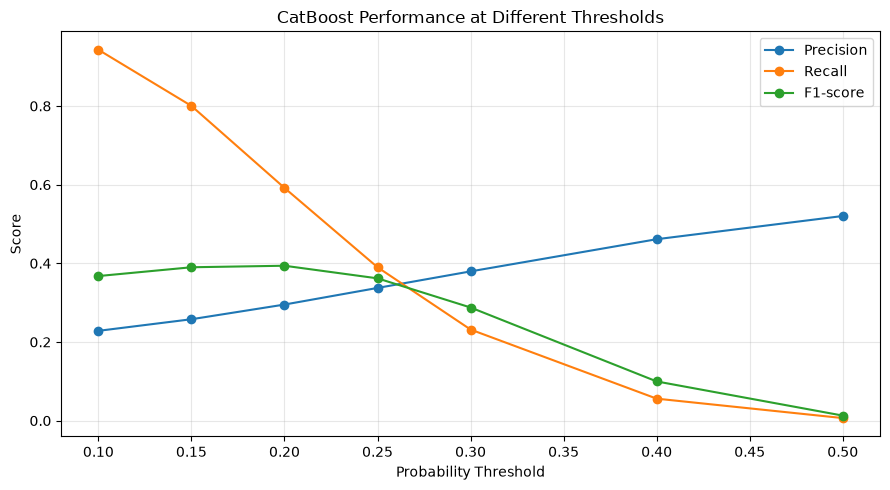

In [47]:
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1_Score"],
    marker="o",
    label="F1-score"
)

plt.xlabel("Probability Threshold")
plt.ylabel("Score")
plt.title("CatBoost Performance at Different Thresholds")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [48]:
print(
    threshold_df[
        ["Threshold", "Accuracy", "Precision", "Recall", "F1_Score"]
    ].to_string(index=False)
)


 Threshold  Accuracy  Precision   Recall  F1_Score
      0.50  0.794136   0.520290 0.006467  0.012774
      0.40  0.792099   0.461252 0.055858  0.099648
      0.30  0.763724   0.379446 0.231573  0.287616
      0.25  0.716607   0.337380 0.389942  0.361762
      0.20  0.624797   0.295108 0.591721  0.393812
      0.15  0.484308   0.257782 0.800184  0.389942
      0.10  0.331687   0.228287 0.942989  0.367586


In [49]:
# Predict on the test set
y_pred_rf = random_forest_model.predict(X_test)
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

Confusion Matrix:
[[130701  83320]
 [ 22005  33511]]

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.61      0.71    214021
           1       0.29      0.60      0.39     55516

    accuracy                           0.61    269537
   macro avg       0.57      0.61      0.55    269537
weighted avg       0.74      0.61      0.65    269537



In [50]:
# Get the fitted preprocessing step and Random Forest model
preprocessor_fitted = random_forest_model.named_steps["preprocessor"]
rf = random_forest_model.named_steps["model"]


feature_names = preprocessor_fitted.get_feature_names_out()


importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf.feature_importances_
}).sort_values("Importance", ascending=False)

# Show thee top 20 importance
importance_df.head(20)

,Feature,Importance
1,numeric__fico_n,0.353676
2,numeric__dti_n,0.213246
0,numeric__loan_amnt,0.154249
29,categorical__home_ownership_n_MORTGAGE,0.057021
32,categorical__home_ownership_n_RENT,0.056497
16,categorical__purpose_credit_card,0.032425
14,categorical__emp_length_NI,0.031267
17,categorical__purpose_debt_consolidation,0.012294
26,categorical__purpose_small_business,0.010945
4,categorical__emp_length_10+ years,0.007548


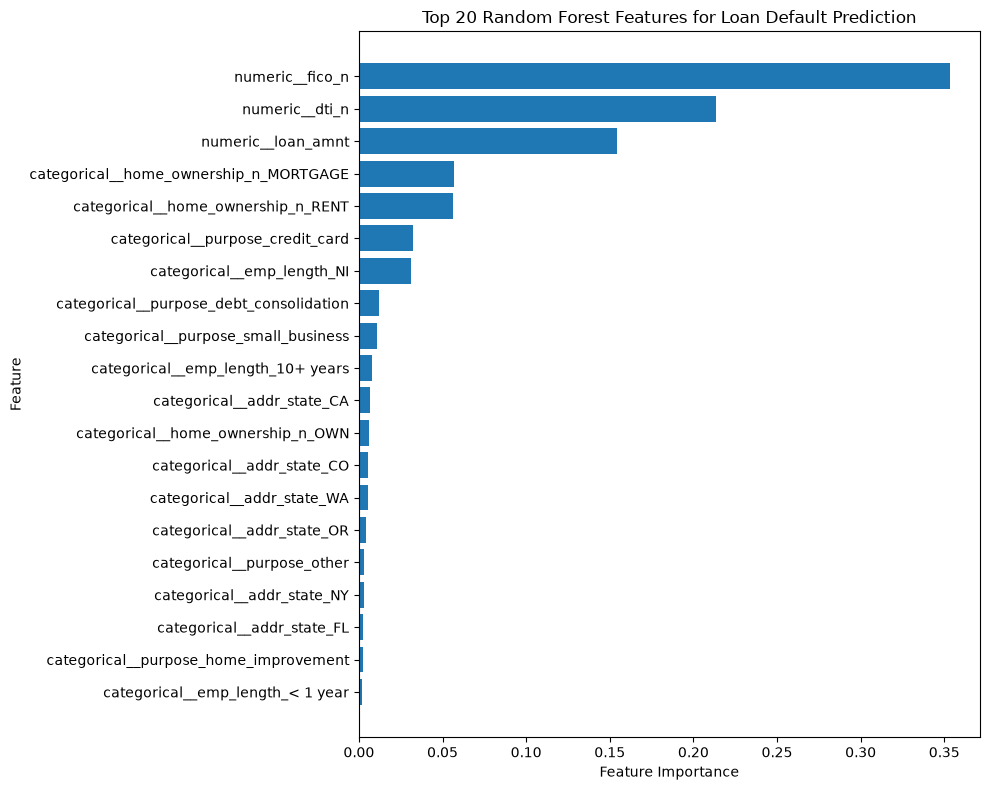

In [51]:
top_20 = importance_df.head(20).sort_values("Importance")

plt.figure(figsize=(10, 8))
plt.barh(top_20["Feature"], top_20["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 20 Random Forest Features for Loan Default Prediction")
plt.tight_layout()
plt.show()

In [53]:
import joblib
import os

os.makedirs("model", exist_ok=True)

joblib.dump(random_forest_model, "model/default_model.joblib", compress=3)
joblib.dump(list(X_train.columns), "model/features.joblib")

['model/features.joblib']

In [55]:
import os

os.makedirs("data", exist_ok=True)
df.to_parquet("data/loans_clean.parquet")